In [9]:
import pandas as pd
df=pd.read_csv("mail_customers.csv")
print(df.head())
x=df[["CustomerIDAge","Annual_Income_k","Spending_Score"]]

   CustomerIDAge  Unnamed: 1  Annual_Income_k  Spending_Score
0              1          20               28              86
1              2          34               90              73
2              3          60               90              35
3              4          46               20              26
4              5          26               22              60


In [10]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
print(x_scaled[:5])

[[-1.64750894 -0.84206755  1.27598617]
 [-1.47408695  1.35617196  0.81521339]
 [-1.30066495  1.35617196 -0.5316609 ]
 [-1.12724296 -1.12571136 -0.85065745]
 [-0.95382097 -1.05480041  0.3544406 ]]


C:\Users\ITLAB\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


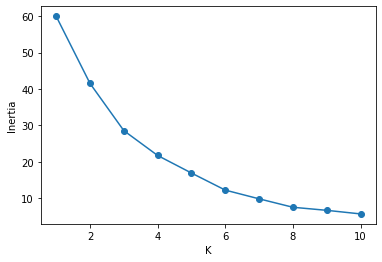

In [11]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for K in range(1, 11):
   km = KMeans(n_clusters=K, random_state=42 ,n_init=10)
   km.fit(x_scaled)
   inertia.append(km.inertia_)
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("K")
plt.ylabel("Inertia")
plt.show()

In [20]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans.fit(x_scaled)

df["cluster"] = kmeans.labels_

print(df["cluster"].value_counts())


1    5
0    5
3    4
2    3
4    3
Name: cluster, dtype: int64


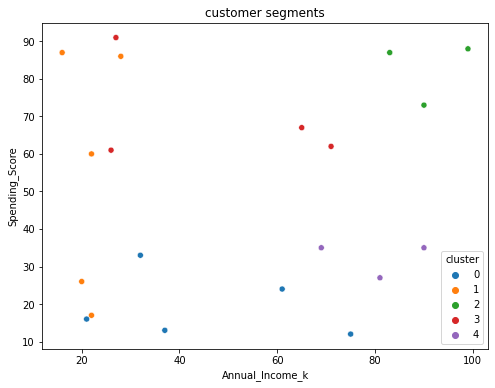

In [24]:
import seaborn as  sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
sns.scatterplot(data=df,x="Annual_Income_k",y="Spending_Score",hue="cluster",palette="tab10")
plt.title("customer segments")
plt.show()

In [26]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
x_pca=pca.fit_transform(x_scaled)
print("Explained variance ratio:",pca.explained_variance_ratio_)

Explained variance ratio: [0.44542076 0.31447221]


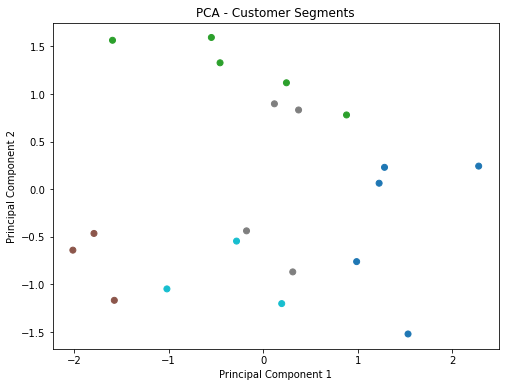

In [27]:
plt.figure(figsize=(8,6))
plt.scatter(
x_pca[:, 0],
x_pca[:, 1],
    c=df["cluster"],
    cmap="tab10"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Customer Segments")
plt.show()